In [17]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
import joblib
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [18]:
PATH = r"E:\satdata\Custom\yucatan_sst_chlor_cdomslope_ssl_bathy_2010-2019_v4.pkl"
MODEL_PATH = r"F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\models\iforest_pipeline5.joblib"

In [19]:
with open(PATH, "rb") as f:
    blob = pickle.load(f)

df = blob["data"]
metadata = blob["metadata"]
df = df[(df.index.year >= 2010) & (df.index.year <= 2019)]

grid_shape = np.asarray(df["sst"].iloc[0]).shape

def shape_ok(a):
    return a is not None and np.asarray(a).shape == grid_shape

In [20]:
features = ["sst_anom", "ssl_anom"]
cols = ["sst", "chlorophyll", "ssl", "cdom_412", "cdom_slope_275_295", "cdom_slope_300_600"]
keep = df[cols].map(shape_ok).all(axis=1)
df = df[keep]

sst_stack   = np.stack(df["sst"].to_numpy()).astype(float)
chlor_stack = np.stack(df["chlorophyll"].to_numpy()).astype(float)
ssl_stack   = np.stack(df["ssl"].to_numpy()).astype(float)
cdom412_stack = np.stack(df["cdom_412"].to_numpy()).astype(float)
cdom_slope1_stack = np.stack(df["cdom_slope_275_295"].to_numpy()).astype(float)
cdom_slope2_stack = np.stack(df["cdom_slope_300_600"].to_numpy()).astype(float)

print(f"Loaded {len(df):,} days, grid shape {grid_shape}")

def same_day_anomaly(stack):
    daily_median = np.nanmedian(stack, axis=(1, 2), keepdims=True)
    return stack - daily_median

sst_anom_stack = same_day_anomaly(sst_stack)
ssl_anom_stack = same_day_anomaly(ssl_stack)

Loaded 3,651 days, grid shape (250, 250)


In [21]:
blob['data'].columns

Index(['sst', 'sst_n_points', 'chlorophyll', 'chlor_n_points', 'cdom_412',
       'cdom_412_n_points', 'cdom_slope_275_295',
       'cdom_slope_275_295_n_points', 'cdom_slope_300_600',
       'cdom_slope_300_600_n_points', 'ssl', 'ssl_n_points'],
      dtype='object')

In [22]:
bundle = joblib.load(MODEL_PATH)
iforest_pipeline = bundle["iforest_pipeline"]
features = bundle.get("features", features)

preprocess = iforest_pipeline.named_steps["preprocess"]
iforest = iforest_pipeline.named_steps["iforest"]
print(f"Loaded pipeline from {MODEL_PATH}")
print(f"Features: {features}")

Loaded pipeline from F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\models\iforest_pipeline5.joblib
Features: ['sst_anom', 'ssl_anom']


In [23]:
start_date = pd.Timestamp("2018-12-01")
end_date = pd.Timestamp("2018-12-30")
percentile_u = 90
percentile_n = 80

In [24]:
window_mask = (df.index >= start_date) & (df.index <= end_date)
n_days = int(window_mask.sum())
if n_days == 0:
    raise ValueError(f"No valid days found between {start_date.date()} and {end_date.date()}")

with np.errstate(invalid="ignore"):
    mean_sst_anom = np.nanmean(sst_anom_stack[window_mask], axis=0)
    mean_ssl_anom = np.nanmean(ssl_anom_stack[window_mask], axis=0)
    mean_chlor    = np.nanmean(chlor_stack[window_mask], axis=0)
    mean_cdom412  = np.nanmean(cdom412_stack[window_mask], axis=0)
    mean_slope1   = np.nanmean(cdom_slope1_stack[window_mask], axis=0)
    mean_slope2   = np.nanmean(cdom_slope2_stack[window_mask], axis=0)

valid_2d = (
    ~np.isnan(mean_sst_anom) & ~np.isnan(mean_ssl_anom)
    & ~np.isnan(mean_chlor) & (mean_chlor > 0)
    & ~np.isnan(mean_cdom412) & ~np.isnan(mean_slope1) & ~np.isnan(mean_slope2)
)
row_w, col_w = np.where(valid_2d)

X_raw = pd.DataFrame({
    "sst_anom": mean_sst_anom[valid_2d],
    "ssl_anom": mean_ssl_anom[valid_2d],
    "chlorophyll": mean_chlor[valid_2d],
    "cdom_412": mean_cdom412[valid_2d],
    "cdom_slope_275_295": mean_slope1[valid_2d],
    "cdom_slope_300_600": mean_slope2[valid_2d],
})

X_window = X_raw[features]
X_window_transformed = preprocess.transform(X_window)

anomaly_score = -iforest.decision_function(X_window_transformed)
threshold_u = np.percentile(anomaly_score, percentile_u)
threshold_n = np.percentile(anomaly_score, percentile_n)
raw_anomaly = anomaly_score >= threshold_u

sst_anom_z = X_window_transformed["anom__sst_anom"].to_numpy()
ssl_anom_z = X_window_transformed["anom__ssl_anom"].to_numpy()

is_upwelling = raw_anomaly & (sst_anom_z < -0.5) & (ssl_anom_z < 0.75)
non_upwelling_mask = anomaly_score < threshold_n

In [25]:
print(f"\n--- Window: {start_date.date()} to {end_date.date()} ({n_days} days averaged) ---")
print(f"Total Valid Pixels: {len(X_raw):,}")
print(f"Upwelling Pixels: {is_upwelling.sum():,} \t Non-Anomaly Pixels: {non_upwelling_mask.sum():,}\n")

print(f"Mean: Upwelling (>{percentile_u}%) vs Non-Anomaly (<{percentile_n}%)")
labels = {
    "sst_anom": "SST anom (°C)",
    "ssl_anom": "SSL anom (m)",
    "chlorophyll": "Chlorophyll (mg/m³)",
    "cdom_412": "CDOM 412",
    "cdom_slope_275_295": "CDOM slope 275-295",
    "cdom_slope_300_600": "CDOM slope 300-600",
}
for col, label in labels.items():
    up_mean = X_raw.loc[is_upwelling, col].mean()
    non_mean = X_raw.loc[non_upwelling_mask, col].mean()
    print(f"{label:22s} | Upwelling: {up_mean:8.4f} | Non-Anomaly: {non_mean:8.4f} | Ratio: {up_mean/non_mean:8.4f}")


--- Window: 2018-12-01 to 2018-12-30 (30 days averaged) ---
Total Valid Pixels: 45,053
Upwelling Pixels: 5 	 Non-Anomaly Pixels: 36,041

Mean: Upwelling (>90%) vs Non-Anomaly (<80%)
SST anom (°C)          | Upwelling:  -1.4850 | Non-Anomaly:  -0.0635 | Ratio:  23.3908
SSL anom (m)           | Upwelling:   0.0775 | Non-Anomaly:   0.0064 | Ratio:  12.0673
Chlorophyll (mg/m³)    | Upwelling:   2.6728 | Non-Anomaly:   1.0227 | Ratio:   2.6134
CDOM 412               | Upwelling:   0.1580 | Non-Anomaly:   0.0882 | Ratio:   1.7916
CDOM slope 275-295     | Upwelling:   0.0271 | Non-Anomaly:   0.0330 | Ratio:   0.8213
CDOM slope 300-600     | Upwelling:   0.0210 | Non-Anomaly:   0.0229 | Ratio:   0.9156


In [26]:
year_mask = df.index.year == 2018

with np.errstate(invalid="ignore"):
    sst_anom_year = sst_anom_stack[year_mask]
    ssl_anom_year = ssl_anom_stack[year_mask]

valid_year = ~np.isnan(sst_anom_year) & ~np.isnan(ssl_anom_year)

X_year = pd.DataFrame({
    "sst_anom": sst_anom_year[valid_year],
    "ssl_anom": ssl_anom_year[valid_year],
})[features]

X_year_transformed = preprocess.transform(X_year)
anomaly_score_year = -iforest.decision_function(X_year_transformed)

print(f"2018: {valid_year.sum():,} valid (day, pixel) samples across {year_mask.sum()} days")

2018: 16,546,180 valid (day, pixel) samples across 365 days


Percentile |      Score
        5% |    -0.1337
       10% |    -0.1296
       15% |    -0.1249
       20% |    -0.1203
       25% |    -0.1150
       30% |    -0.1078
       35% |    -0.0999
       40% |    -0.0915
       45% |    -0.0818
       50% |    -0.0695
       55% |    -0.0560
       60% |    -0.0396
       65% |    -0.0207
       70% |    -0.0085
       75% |     0.0006
       80% |     0.0112
       85% |     0.0255
       90% |     0.0445
       95% |     0.0745


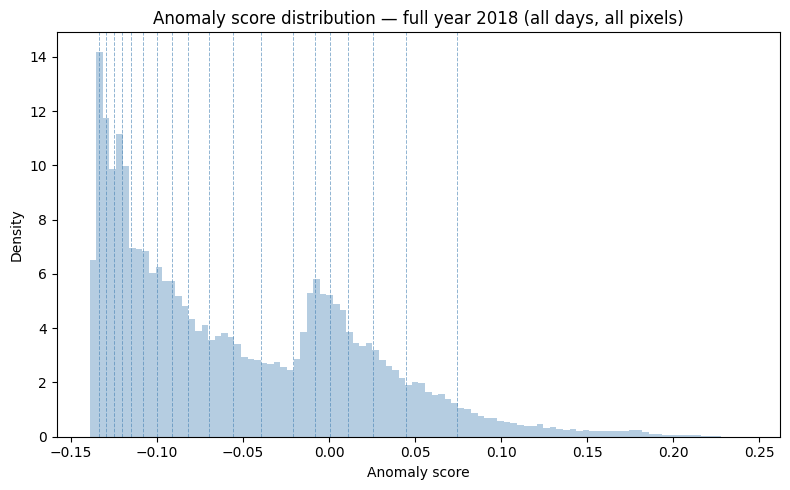

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(anomaly_score_year, bins=100, density=True, alpha=0.4, color="steelblue")

percentiles_to_mark = np.arange(5, 100, 5)  # 5, 10, ..., 95

print(f"{'Percentile':>10s} | {'Score':>10s}")
for p in percentiles_to_mark:
    val = np.percentile(anomaly_score_year, p)
    ax.axvline(val, linestyle="--", lw=0.7, color="steelblue", alpha=0.6)
    print(f"{p:>9d}% | {val:>10.4f}")

ax.set_xlabel("Anomaly score")
ax.set_ylabel("Density")
ax.set_title("Anomaly score distribution — full year 2018 (all days, all pixels)")
fig.tight_layout()
plt.show()

Primary knee: ~86.5th percentile, score = 0.0302


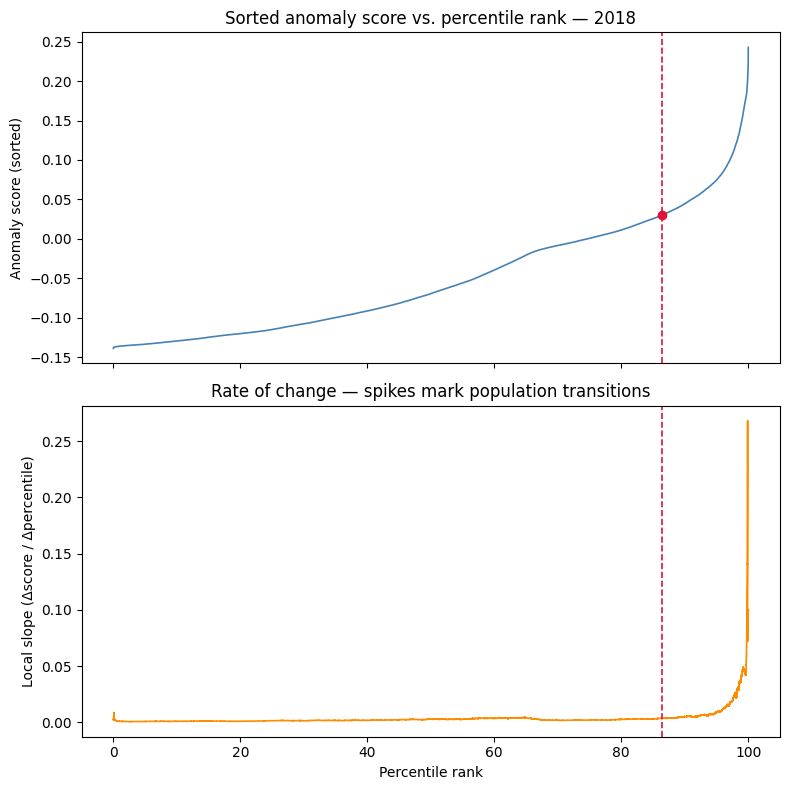

In [28]:
sorted_scores = np.sort(anomaly_score_year)
n = len(sorted_scores)
rank_pct = np.linspace(0, 100, n)

# light smoothing so the derivative isn't pure noise
window = max(n // 500, 5)
smoothed = pd.Series(sorted_scores).rolling(window, center=True, min_periods=1).mean().to_numpy()

# kneedle-style knee detection: normalize both axes 0-1, find point(s)
# of max perpendicular distance from the straight line connecting the endpoints
x_norm = (rank_pct - rank_pct.min()) / (rank_pct.max() - rank_pct.min())
y_norm = (smoothed - smoothed.min()) / (smoothed.max() - smoothed.min())
diff = y_norm - x_norm

# the biggest positive deviation = knee where curve pulls away below the diagonal
# (transition out of the flat/dense population)
knee_idx = np.argmax(np.abs(diff))
knee_pct = rank_pct[knee_idx]
knee_val = sorted_scores[knee_idx]

# local slope (score change per percentile step) highlights every transition, not just the biggest
slope = np.gradient(smoothed, rank_pct)

print(f"Primary knee: ~{knee_pct:.1f}th percentile, score = {knee_val:.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

ax1.plot(rank_pct, sorted_scores, color="steelblue", lw=1.2)
ax1.axvline(knee_pct, color="crimson", lw=1.2, linestyle="--")
ax1.scatter([knee_pct], [knee_val], color="crimson", zorder=5)
ax1.set_ylabel("Anomaly score (sorted)")
ax1.set_title("Sorted anomaly score vs. percentile rank — 2018")

ax2.plot(rank_pct, slope, color="darkorange", lw=1.2)
ax2.axvline(knee_pct, color="crimson", lw=1.2, linestyle="--")
ax2.set_xlabel("Percentile rank")
ax2.set_ylabel("Local slope (Δscore / Δpercentile)")
ax2.set_title("Rate of change — spikes mark population transitions")

fig.tight_layout()
plt.show()


SST anom (°C) — value at each percentile (2018, n=16,546,180)
Percentile |      Value
        5% |    -1.5442
       10% |    -1.0802
       20% |    -0.6410
       30% |    -0.3760
       50% |     0.0000
       70% |     0.4051
       80% |     0.7653
       90% |     1.3875
       95% |     1.7696

SSL anom (m) — value at each percentile (2018, n=16,546,180)
Percentile |      Value
        5% |    -0.0766
       10% |    -0.0570
       20% |    -0.0373
       30% |    -0.0242
       50% |     0.0000
       70% |     0.0442
       80% |     0.1274
       90% |     0.3213
       95% |     0.4221


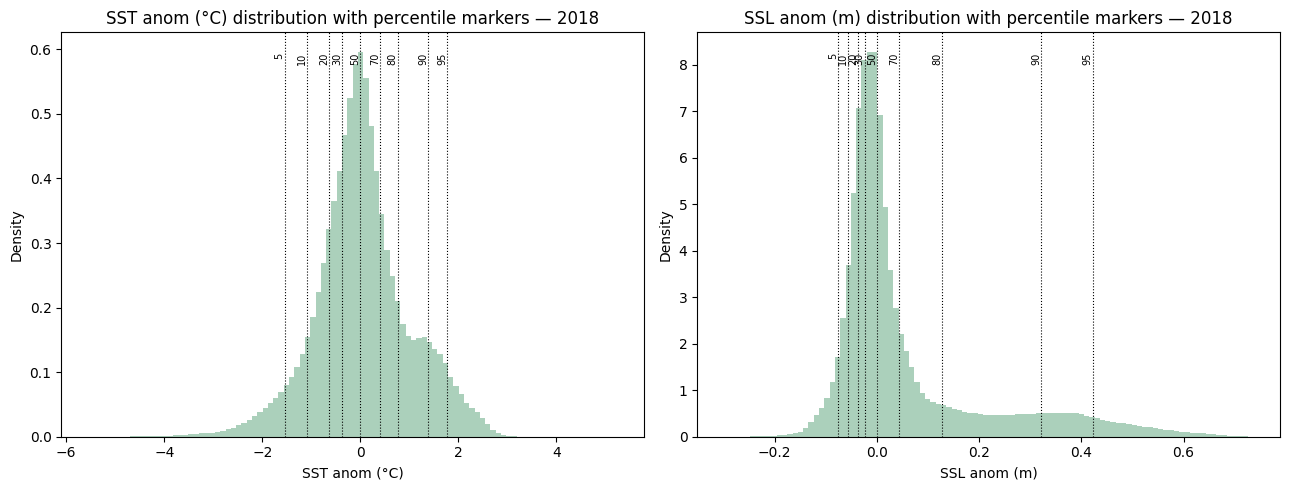

In [29]:
percentiles_to_mark = [5, 10, 20, 30, 50, 70, 80, 90, 95]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, var, arr, label in zip(
    axes,
    ["sst_anom", "ssl_anom"],
    [sst_anom_year[valid_year], ssl_anom_year[valid_year]],
    ["SST anom (°C)", "SSL anom (m)"]
):
    ax.hist(arr, bins=100, density=True, alpha=0.4, color="seagreen")
    print(f"\n{label} — value at each percentile (2018, n={len(arr):,})")
    print(f"{'Percentile':>10s} | {'Value':>10s}")
    for p in percentiles_to_mark:
        val = np.percentile(arr, p)
        ax.axvline(val, color="black", lw=0.8, linestyle=":")
        ax.text(val, ax.get_ylim()[1]*0.95, f"{p}", rotation=90,
                fontsize=7, ha="right", va="top")
        print(f"{p:>9d}% | {val:>10.4f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.set_title(f"{label} distribution with percentile markers — 2018")

fig.tight_layout()
plt.show()

Lower knee (non-anomaly boundary): ~98.9th pct, score=0.1443
Upper knee (upwelling boundary):    ~99.9th pct, score=0.2020
Suggested buffer width: 1.0 percentile points


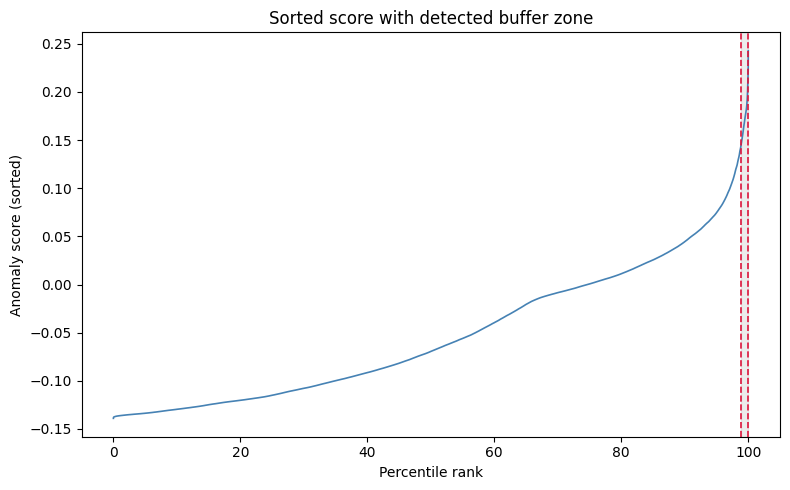

In [30]:
from scipy.signal import find_peaks

# use the same slope array from your knee-plot cell
abs_slope = np.abs(slope)
baseline = np.median(abs_slope)   # typical "flat" slope level
noise = np.std(abs_slope)

# find local maxima in slope that clearly exceed the flat baseline
peaks, props = find_peaks(abs_slope, height=baseline + 2 * noise, distance=n // 100)

peak_pcts = rank_pct[peaks]
peak_vals = sorted_scores[peaks]
peak_heights = props["peak_heights"]

# keep the two most prominent peaks (by slope height)
top2 = peaks[np.argsort(peak_heights)[-2:]]
top2 = np.sort(top2)  # order by position, not height

if len(top2) == 2:
    lo_idx, hi_idx = top2
    print(f"Lower knee (non-anomaly boundary): ~{rank_pct[lo_idx]:.1f}th pct, score={sorted_scores[lo_idx]:.4f}")
    print(f"Upper knee (upwelling boundary):    ~{rank_pct[hi_idx]:.1f}th pct, score={sorted_scores[hi_idx]:.4f}")
    print(f"Suggested buffer width: {rank_pct[hi_idx] - rank_pct[lo_idx]:.1f} percentile points")
else:
    print(f"Only found {len(top2)} clear knee(s) — try lowering the height threshold (e.g. baseline + 1*noise)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rank_pct, sorted_scores, color="steelblue", lw=1.2)
for idx in top2:
    ax.axvline(rank_pct[idx], color="crimson", lw=1.2, linestyle="--")
ax.axvspan(rank_pct[top2[0]], rank_pct[top2[-1]], color="gray", alpha=0.15, label="buffer zone")
ax.set_xlabel("Percentile rank")
ax.set_ylabel("Anomaly score (sorted)")
ax.set_title("Sorted score with detected buffer zone")
fig.tight_layout()
plt.show()

Confidence threshold: 0.9
Buffer zone: score [-0.1390, -0.0696]  (~0.0th to ~50.0th percentile)
Non-anomaly: 4,904,282 pts | Buffer: 3,363,288 pts | Anomaly: 8,278,610 pts


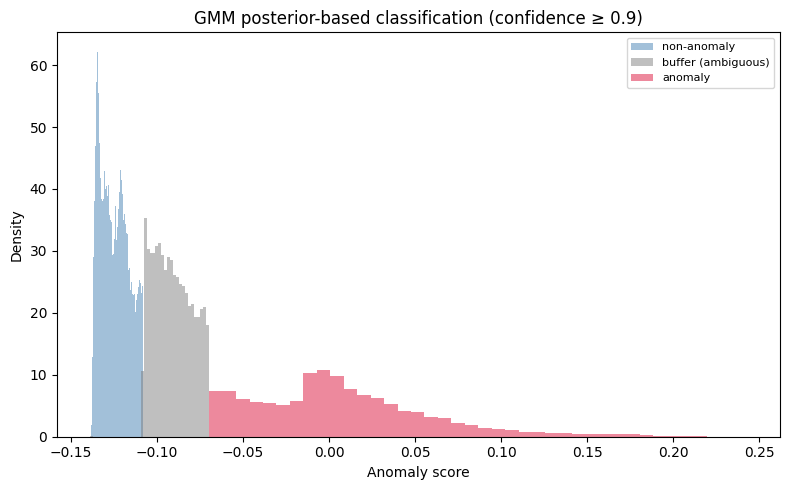

In [32]:
from sklearn.mixture import GaussianMixture
from scipy import stats

gmm = GaussianMixture(n_components=2, random_state=0).fit(anomaly_score_year.reshape(-1, 1))
order = np.argsort(gmm.means_.ravel())  # low component first

posterior = gmm.predict_proba(anomaly_score_year.reshape(-1, 1))[:, order]
max_posterior = posterior.max(axis=1)
dominant_component = posterior.argmax(axis=1)  # 0 = low (non-anom), 1 = high (anom)

confidence_threshold = 0.9  # how "sure" a point must be to NOT be in the buffer
ambiguous = max_posterior < confidence_threshold

buffer_scores = anomaly_score_year[ambiguous]
non_anomaly_scores = anomaly_score_year[~ambiguous & (dominant_component == 0)]
anomaly_scores_ = anomaly_score_year[~ambiguous & (dominant_component == 1)]

lower_bound = buffer_scores.min() if len(buffer_scores) else np.nan
upper_bound = buffer_scores.max() if len(buffer_scores) else np.nan
lower_pct = stats.percentileofscore(anomaly_score_year, lower_bound)
upper_pct = stats.percentileofscore(anomaly_score_year, upper_bound)

print(f"Confidence threshold: {confidence_threshold}")
print(f"Buffer zone: score [{lower_bound:.4f}, {upper_bound:.4f}]  "
      f"(~{lower_pct:.1f}th to ~{upper_pct:.1f}th percentile)")
print(f"Non-anomaly: {len(non_anomaly_scores):,} pts | "
      f"Buffer: {len(buffer_scores):,} pts | "
      f"Anomaly: {len(anomaly_scores_):,} pts")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(non_anomaly_scores, bins=80, density=True, alpha=0.5, color="steelblue", label="non-anomaly")
ax.hist(buffer_scores, bins=40, density=True, alpha=0.5, color="gray", label="buffer (ambiguous)")
ax.hist(anomaly_scores_, bins=40, density=True, alpha=0.5, color="crimson", label="anomaly")
ax.set_xlabel("Anomaly score")
ax.set_ylabel("Density")
ax.set_title(f"GMM posterior-based classification (confidence ≥ {confidence_threshold})")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()